In [1]:
import pandas as pd
import numpy as np 
import warnings
import seaborn as sns
import math
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
import lab_utils_uni
import lab_utils_common
from lab_utils_uni import plt_intuition, plt_stationary, plt_update_onclick, soup_bowl,plt_gradients
from scipy.stats import pearsonr
import kagglehub
import os
import glob


In [2]:
pd.set_option('display.float_format',lambda x : '%.2f' % x)


In [3]:
real_estate_df = pd.read_csv("C:/Users/leste/OneDrive/Desktop/Microsoft VS Code/Github/Data-Analytics-Projects-/Data Files/Multivariate Regression/Real_estate.csv")

In [5]:
real_estate_df

,Age,Distance,Stores,Price
0,32.00,84.88,10,37.90
1,19.50,306.59,9,42.20
2,13.30,561.98,5,47.30
3,13.30,561.98,5,54.80
4,5.00,390.57,5,43.10
...,...,...,...,...
409,13.70,4082.01,0,15.40
410,5.60,90.46,9,50.00
411,18.80,390.97,7,40.60
412,8.10,104.81,5,52.50


In [6]:
real_estate_df.describe()

,Age,Distance,Stores,Price
count,414.00,414.00,414.00,414.00
mean,17.71,1083.89,4.09,37.98
std,11.39,1262.11,2.95,13.61
min,0.00,23.38,0.00,7.60
25%,9.03,289.32,1.00,27.70
50%,16.10,492.23,4.00,38.45
75%,28.15,1454.28,6.00,46.60
max,43.80,6488.02,10.00,117.50


> The Mean of the Age , Distance & Store features are much lower than the max value which means there is an outlier

In [7]:
real_estate_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Age       414 non-null    float64
 1   Distance  414 non-null    float64
 2   Stores    414 non-null    int64  
 3   Price     414 non-null    float64
dtypes: float64(3), int64(1)
memory usage: 13.1 KB


<Axes: >

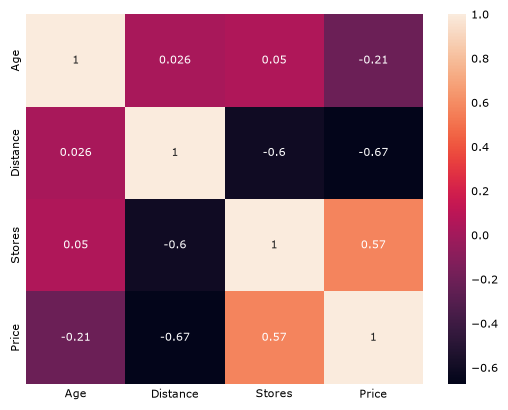

In [8]:
sns.heatmap(real_estate_df.corr(), annot = True)

> Price has a negative correlation with Age , Distance but has positive correlation with number of stores , which is not a strong correlation

> Testing out Pearson correlation and checking the confidence rate

In [9]:
pearson_correlation = pearsonr(x = real_estate_df['Stores'], y = real_estate_df['Price'])

In [10]:
pearson_correlation

PearsonRResult(statistic=np.float64(0.5710049111111485), pvalue=np.float64(3.413483340496057e-37))

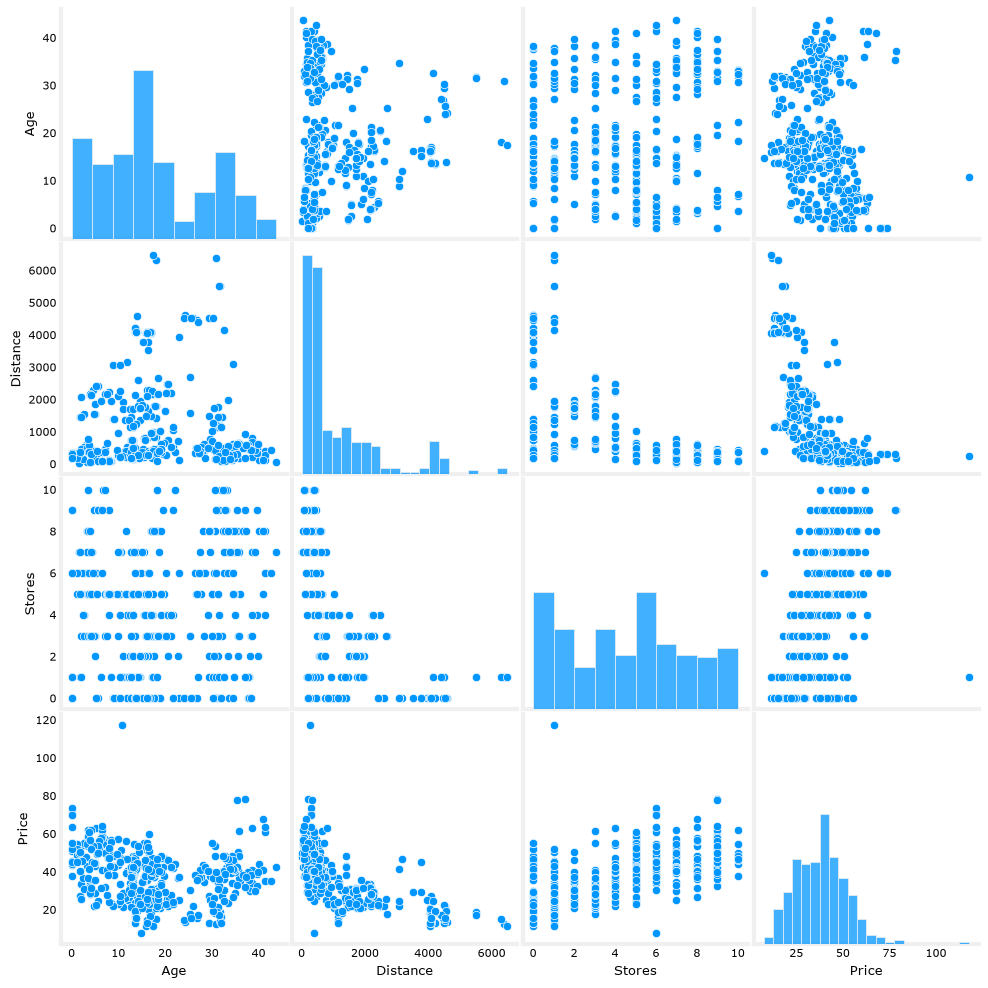

In [11]:
sns.pairplot(real_estate_df)
plt.show()

In [12]:
real_estate_final_df = real_estate_df

### Multivariate Linear Regression

In [13]:
x_multi_features = real_estate_final_df[['Age','Distance','Stores']]
y_features = real_estate_final_df[['Price']]

In [14]:
standard_scaling = StandardScaler()

In [15]:
x_multi_features_stand = standard_scaling.fit_transform(x_multi_features)
y_features_stand = standard_scaling.fit_transform(y_features)

> Splitting in into train, validation and testing for multivariate features

In [16]:
x_multi_train , x_multi_temp , y_multi_train , y_multi_temp = train_test_split(x_multi_features_stand,y_features_stand, test_size = 0.2 , random_state = 42 )
x_multi_val , x_multi_test , y_multi_val , y_multi_test = train_test_split(x_multi_temp,y_multi_temp, test_size = 0.4 , random_state = 50)

In [17]:
multi_model = LinearRegression()

In [18]:
multi_model.fit(x_multi_train,y_multi_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 3)","[[-0.22,-0.51, 0.27]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.01]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[22.71,18.12,11.12]"


### Model Accuracy for Univariate and Multivariate Regression

In [19]:
training_accuracy = multi_model.score(x_multi_train,y_multi_train)
validation_accuracy = multi_model.score(x_multi_val,y_multi_val)

In [20]:
print(f"The Accuracy of the Training model : {training_accuracy}")
print(f"The Accuracy of the Validation model : {validation_accuracy}")

The Accuracy of the Training model : 0.5146436173066767
The Accuracy of the Validation model : 0.7696409799469078


In [21]:
y_train_pred = multi_model.predict(x_multi_train) # predicting the training features
y_val_pred = multi_model.predict(x_multi_val) # predicting the validation features

> Checking Mean Squared error for both training and validation


In [ ]:
print(f"The Mean squared error for training predictions : {mean_squared_error(y_multi_train,y_train_pred)}")
print(f"The Mean squared error for validation predictions : {mean_squared_error(y_multi_val,y_val_pred)}")

The Mean squared error for training predictions : 0.49429456430939245
The Mean squared error for validation predictions : 0.17642953707128828


In [24]:
print(f"The Mean squared error for training predictions : {mean_absolute_error(y_multi_train,y_train_pred)}")
print(f"The Mean squared error for validation predictions : {mean_absolute_error(y_multi_val,y_val_pred)}")

The Mean squared error for training predictions : 0.4945638820890999
The Mean squared error for validation predictions : 0.33301405005575957


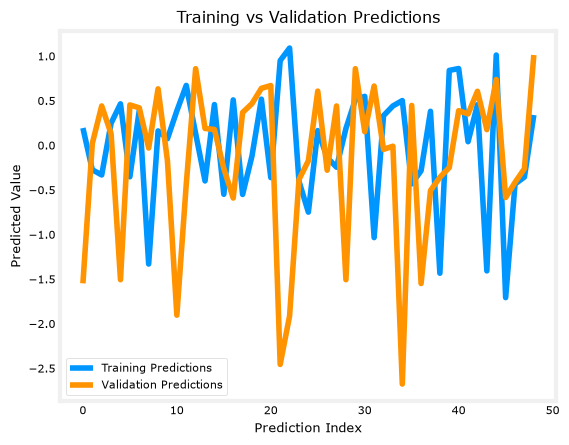

In [ ]:
# Plotting the y_training_predictions y_validation_predictions

import numpy as np
import matplotlib.pyplot as plt

plt.plot(np.arange(len(y_train_pred[0:49])), y_train_pred[0:49],
         label="Training Predictions")

plt.plot(np.arange(len(y_val_pred[0:49])), y_val_pred[0:49],
         label="Validation Predictions")

plt.xlabel("Prediction Index")
plt.ylabel("Predicted Value")
plt.title("Training vs Validation Predictions")
plt.legend()
plt.show()